# 5) Visualisation Notebook
- This notebook loads, preprocesses, and visualises impedance datasets.
- It produces Nyquist and Bode plots for both **raw measurement data** and **simulated data**.



# 1. Setup
Import required modules and ensure the `src/` directory is accessible.

In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

# Add src folder to path
sys.path.append(str(Path("../src")))

from visualization.nyquist import nyquist_from_csv
from visualization.bode import bode_from_csv
from processing.preprocessing import preprocess, save_processed

# 2. Preprocess Raw Measurement Data
Load the raw CSV file, clean it, and save the processed version.

In [2]:
raw_path = "../data/raw/measurement1.csv"
processed_path = "../data/processed/measurement1_clean.csv"

df = preprocess(raw_path, smooth=True, window=5)
save_processed(df, processed_path)

# 3. Visualise Cleaned Measurement Data
Generate Nyquist and Bode plots using the processed dataset.

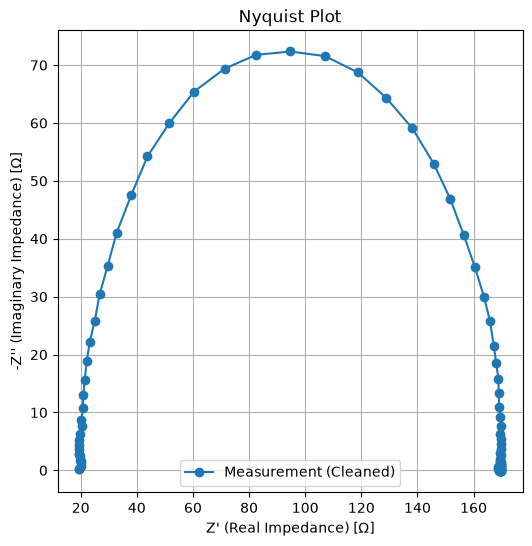

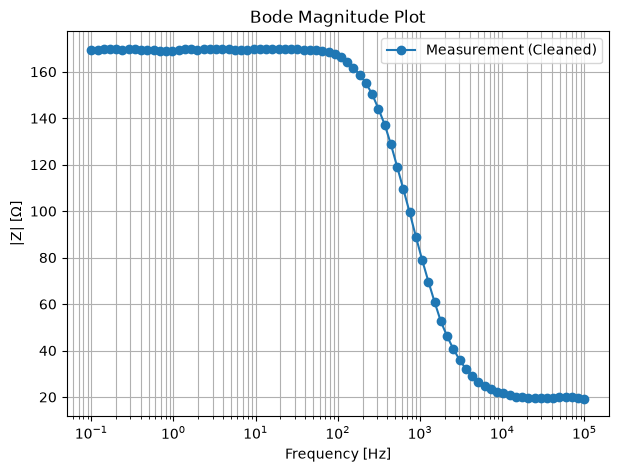

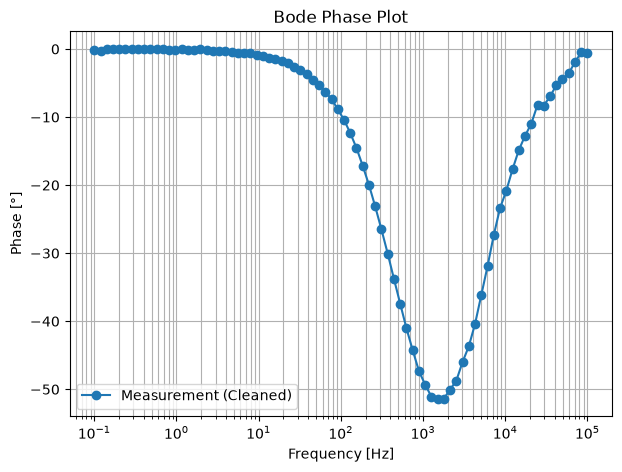

In [3]:
nyquist_from_csv(
    filepath=processed_path,
    label="Measurement (Cleaned)",
    save_path="../results/figures/nyquist_measurement_clean.png"
)

bode_from_csv(
    filepath=processed_path,
    label="Measurement (Cleaned)",
    save_mag_path="../results/figures/bode_mag_measurement_clean.png",
    save_phase_path="../results/figures/bode_phase_measurement_clean.png"
)

# 4. Visualise Simulated RC Data
Plot Nyquist and Bode diagrams for the simulated RC circuit dataset.

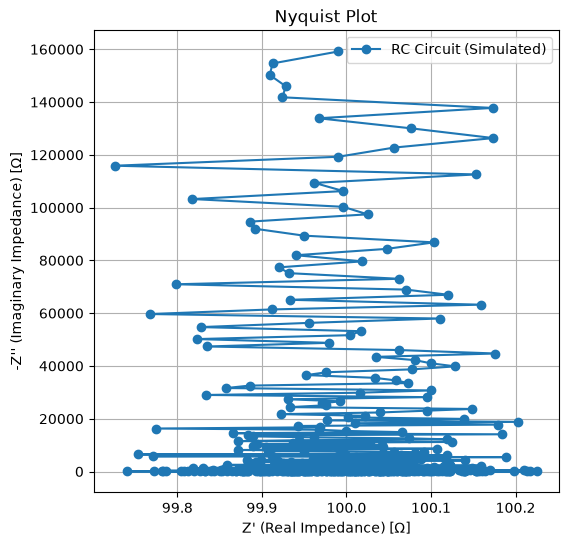

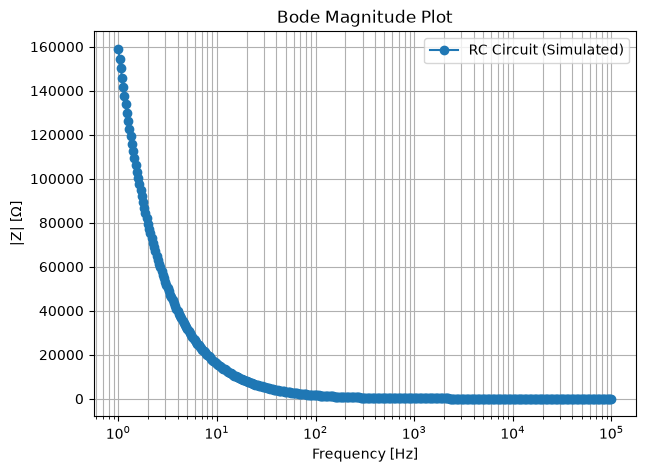

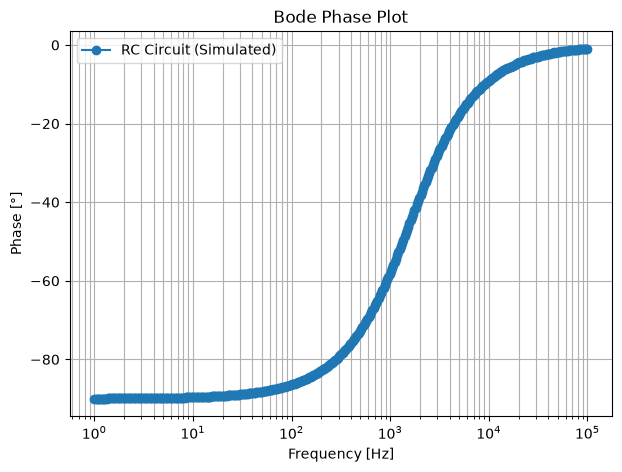

In [4]:
simulated_rc = "../data/simulated/rc_R100_C1uF.csv"

nyquist_from_csv(
    filepath=simulated_rc,
    label="RC Circuit (Simulated)",
    save_path="../results/figures/nyquist_rc.png"
)

bode_from_csv(
    filepath=simulated_rc,
    label="RC Circuit (Simulated)",
    save_mag_path="../results/figures/bode_mag_rc.png",
    save_phase_path="../results/figures/bode_phase_rc.png"
)

# 5. Multi‑Dataset Nyquist Comparison
Compare resistor, capacitor, RC circuit, and cleaned measurement data on a single Nyquist plot.

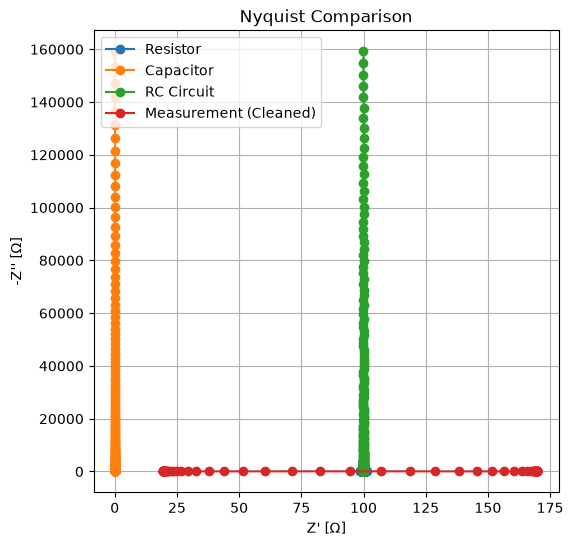

In [5]:
datasets = [
    ("../data/simulated/resistor_R100.csv", "Resistor"),
    ("../data/simulated/capacitor_C1uF.csv", "Capacitor"),
    ("../data/simulated/rc_R100_C1uF.csv", "RC Circuit"),
    (processed_path, "Measurement (Cleaned)")
]

plt.figure(figsize=(6, 6))
for path, label in datasets:
    df = pd.read_csv(path)
    plt.plot(df["real"], -df["imag"], "o-", label=label)

plt.xlabel("Z' [Ω]")
plt.ylabel("-Z'' [Ω]")
plt.title("Nyquist Comparison")
plt.grid(True)
plt.legend()
plt.show()